Understand problem
Predict whether a loan application will default or not.

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("Loan_Default.csv")

In [3]:
df.head()

,ID,year,loan_limit,Gender,approv_in_adv,loan_type,loan_purpose,Credit_Worthiness,open_credit,business_or_commercial,...,credit_type,Credit_Score,co-applicant_credit_type,age,submission_of_application,LTV,Region,Security_Type,Status,dtir1
0,24890,2019,cf,Sex Not Available,nopre,type1,p1,l1,nopc,nob/c,...,EXP,758,CIB,25-34,to_inst,98.728814,south,direct,1,45.0
1,24891,2019,cf,Male,nopre,type2,p1,l1,nopc,b/c,...,EQUI,552,EXP,55-64,to_inst,NaN,North,direct,1,NaN
2,24892,2019,cf,Male,pre,type1,p1,l1,nopc,nob/c,...,EXP,834,CIB,35-44,to_inst,80.019685,south,direct,0,46.0
3,24893,2019,cf,Male,nopre,type1,p4,l1,nopc,nob/c,...,EXP,587,CIB,45-54,not_inst,69.376900,North,direct,0,42.0
4,24894,2019,cf,Joint,pre,type1,p1,l1,nopc,nob/c,...,CRIF,602,EXP,25-34,not_inst,91.886544,North,direct,0,39.0


In [4]:
print("Shape:", df.shape)

Shape: (148670, 34)


In [5]:

print(df.info())

print(df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 148670 entries, 0 to 148669
Data columns (total 34 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   ID                         148670 non-null  int64  
 1   year                       148670 non-null  int64  
 2   loan_limit                 145326 non-null  str    
 3   Gender                     148670 non-null  str    
 4   approv_in_adv              147762 non-null  str    
 5   loan_type                  148670 non-null  str    
 6   loan_purpose               148536 non-null  str    
 7   Credit_Worthiness          148670 non-null  str    
 8   open_credit                148670 non-null  str    
 9   business_or_commercial     148670 non-null  str    
 10  loan_amount                148670 non-null  int64  
 11  rate_of_interest           112231 non-null  float64
 12  Interest_rate_spread       112031 non-null  float64
 13  Upfront_charges            109028 non-nu

In [7]:
# check target
import matplotlib.pyplot as plt
import seaborn as sns

print(df["Status"].value_counts())

Status
0    112031
1     36639
Name: count, dtype: int64


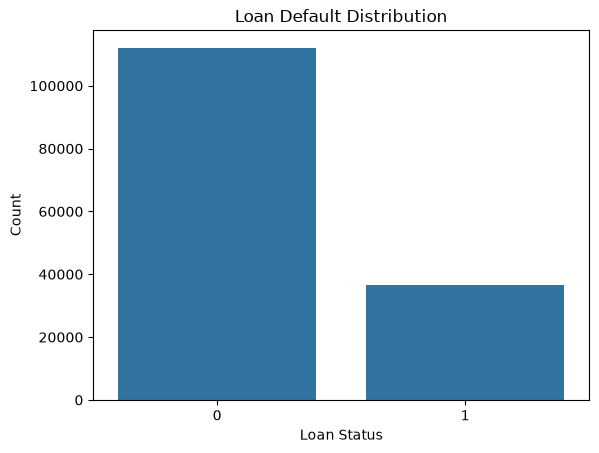

In [8]:
# visualise target
sns.countplot(x="Status", data=df)
plt.title("Loan Default Distribution")
plt.xlabel("Loan Status")
plt.ylabel("Count")
plt.show()


In [10]:
# remove unnecessary column
# remove unnecessary columns
df = df.drop(columns=["ID"], errors="ignore")

In [11]:
# seperate
X = df.drop("Status", axis=1)
y = df["Status"]

In [12]:
#split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [13]:
#numeric vs categorical
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns

print("Numerical Features:")
print(list(numeric_features))
print("\nCategorical Features:")
print(list(categorical_features))

Numerical Features:
['year', 'loan_amount', 'rate_of_interest', 'Interest_rate_spread', 'Upfront_charges', 'term', 'property_value', 'income', 'Credit_Score', 'LTV', 'dtir1']

Categorical Features:
['loan_limit', 'Gender', 'approv_in_adv', 'loan_type', 'loan_purpose', 'Credit_Worthiness', 'open_credit', 'business_or_commercial', 'Neg_ammortization', 'interest_only', 'lump_sum_payment', 'construction_type', 'occupancy_type', 'Secured_by', 'total_units', 'credit_type', 'co-applicant_credit_type', 'age', 'submission_of_application', 'Region', 'Security_Type']


C:\Users\Admin\AppData\Local\Temp\ipykernel_13408\295133235.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [14]:
# preprocess numeric data
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

In [15]:
# preprocess catogoric data
from sklearn.preprocessing import OneHotEncoder

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

In [16]:
# combine preprocess
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [17]:
#transform data
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [19]:
print("Training Shape:", X_train_processed.shape)
print("Testing Shape:", X_test_processed.shape)

print("Training Shape:", X_train_processed.shape)
print("Testing Shape:", X_test_processed.shape)

Training Shape: (118936, 70)
Testing Shape: (29734, 70)
Training Shape: (118936, 70)
Testing Shape: (29734, 70)


In [23]:


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

In [22]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

model = Sequential([
    Dense(128, activation="relu", input_shape=(X_train_processed.shape[1],)),
    Dropout(0.30),
    Dense(64, activation="relu"),
    Dropout(0.30),
    Dense(32, activation="relu"),
    Dense(1, activation="sigmoid")
])

d:\IT STUFF\vs code\DataScience\MACHINE_LEARNING\.venv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [24]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [25]:
history = model.fit(
    X_train_processed,
    y_train,
    epochs=20,
    batch_size=64,
    validation_split=0.20
)

Epoch 1/20
1487/1487 ━━━━━━━━━━━━━━━━━━━━ 17s 6ms/step - accuracy: 0.9578 - loss: 0.1069 - val_accuracy: 0.9958 - val_loss: 0.0130
Epoch 2/20
1487/1487 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - accuracy: 0.9944 - loss: 0.0214 - val_accuracy: 0.9950 - val_loss: 0.0156
Epoch 3/20
1487/1487 ━━━━━━━━━━━━━━━━━━━━ 15s 10ms/step - accuracy: 0.9966 - loss: 0.0126 - val_accuracy: 0.9984 - val_loss: 0.0066
Epoch 4/20
1487/1487 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.9971 - loss: 0.0124 - val_accuracy: 0.9974 - val_loss: 0.0097
Epoch 5/20
1487/1487 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.9972 - loss: 0.0099 - val_accuracy: 0.9979 - val_loss: 0.0090
Epoch 6/20
1487/1487 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - accuracy: 0.9977 - loss: 0.0090 - val_accuracy: 0.9987 - val_loss: 0.0049
Epoch 7/20
1487/1487 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9979 - loss: 0.0080 - val_accuracy: 0.9992 - val_loss: 0.0046
Epoch 8/20
1487/1487 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9978 - loss: 0.

In [26]:
test_loss, test_accuracy = model.evaluate(
    X_test_processed,
    y_test
)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

930/930 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9986 - loss: 0.0075
Test Loss: 0.007452450226992369
Test Accuracy: 0.9986211061477661


In [27]:
predictions = model.predict(X_test_processed)

930/930 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step


In [28]:
predicted_classes = (predictions >= 0.5).astype(int)

In [29]:
accuracy = accuracy_score(y_test, predicted_classes)
print("Accuracy:", accuracy)

Accuracy: 0.9986211071500639


In [30]:
print(classification_report(y_test, predicted_classes))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     22406
           1       0.99      1.00      1.00      7328

    accuracy                           1.00     29734
   macro avg       1.00      1.00      1.00     29734
weighted avg       1.00      1.00      1.00     29734



In [31]:
cm = confusion_matrix(y_test, predicted_classes)
print(cm)

[[22368    38]
 [    3  7325]]


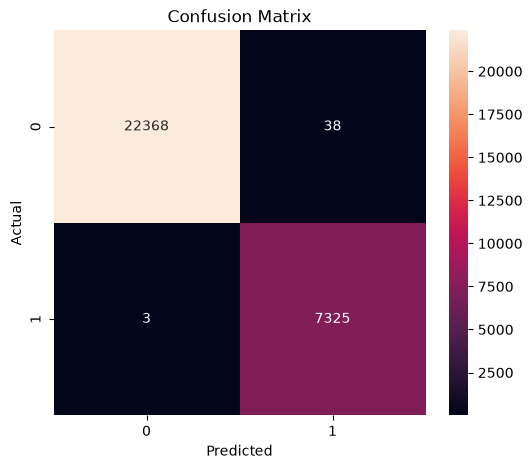

In [32]:
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

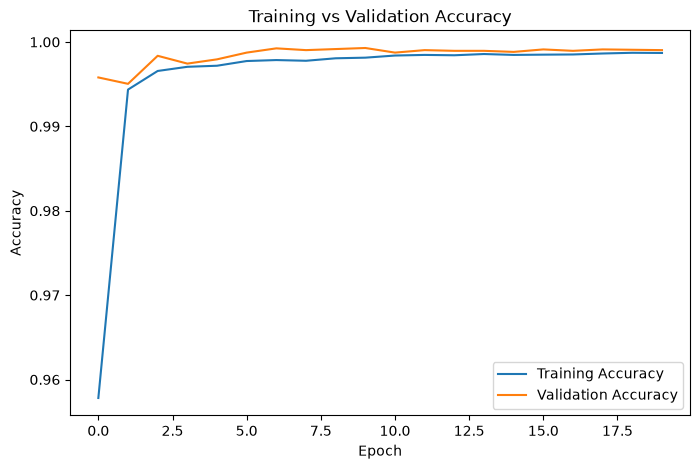

In [33]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.show() 